## 03. Model and Hyperparameter Tuning

In [1]:
from pathlib import Path
import sys

sys.path.append(str(Path.cwd().parents[0]))
from src.validation import top_words_per_class_nb, model_check, top_words_overall_rf
from src.tuning import tune_search, visualize_metrics, show_metrics

In [8]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from src import tuning
import pandas as pd
import numpy as np

df = pd.read_csv('../data/processed/sms_cleaned_data.csv')
df = df[(df['target'] == 0) | (df['target'] == 1)]
df.head(10)

,date,text,carrier,target,punctuation_count,text_count,has_url,has_money_mention,has_phone_in_text,exclamation_count,uppercase_ratio,word_count,year,month
2,2026-03-27 06:23:44.260,papalduhin kita moneytoken ngayon basta bahala...,Smart,1,6,167,0.0,1.0,0.0,0.0,0.071856,22,2026,March
3,2026-02-17 10:25:35.838,boss panalunin kita pinata win moneytoken haba...,Smart,1,11,186,0.0,1.0,0.0,0.0,0.016129,20,2026,February
5,2025-11-15 10:25:41.961,okay makipag deal sayo cash ipapanalo kita mon...,Smart,1,10,195,0.0,1.0,0.0,0.0,0.020513,25,2025,November
7,2025-08-27 09:28:23.142,fex parcel p iisddcddtba reach please contact ...,Smart,1,5,109,0.0,0.0,1.0,0.0,0.119266,10,2025,August
8,2025-08-19 08:57:21.957,smart reminds reward points expire today pleas...,Unknown,1,11,114,1.0,0.0,0.0,0.0,0.043860,11,2025,August
9,2025-08-12 22:16:30.612,landbank iaccess account deducted moneytoken a...,Unknown,1,12,178,1.0,1.0,0.0,0.0,0.095506,11,2025,August
10,2025-08-10 10:04:33.960,smart reminds reward points expire today pleas...,Unknown,1,11,116,1.0,0.0,0.0,0.0,0.043103,11,2025,August
11,2025-08-09 05:25:40.334,smart reminds reward points expire today pleas...,Unknown,1,11,115,1.0,0.0,0.0,0.0,0.043478,11,2025,August
12,2025-08-08 06:19:10.506,smart reminds reward points expire today pleas...,Unknown,1,11,114,1.0,0.0,0.0,0.0,0.043860,11,2025,August
13,2025-08-07 06:29:56.881,smart reminds reward points expire today pleas...,Unknown,1,11,115,1.0,0.0,0.0,0.0,0.043478,11,2025,August


### Data Preprocessing

In [9]:
# used for deduplication in splitting criteria
df['dedup_group_id'] = pd.factorize(df['text'])[0]
binary_cols = ['has_url', 'has_money_mention', 'has_phone_in_text']
numericals = ['exclamation_count', 'text_count', 'word_count',
              'punctuation_count', 'uppercase_ratio']

features = ['text'] + binary_cols + numericals

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(df[features], df['target'], groups=df['dedup_group_id']))

train_data = df.iloc[train_idx].reset_index(drop=True)
test_data = df.iloc[test_idx].reset_index(drop=True)

X_train = train_data[features]
y_train = train_data['target']
X_test = test_data[features]
y_test = test_data['target']

train_groups = train_data['dedup_group_id']

preprocessing = ColumnTransformer([
    ('text', TfidfVectorizer(sublinear_tf=True), 'text'),
    ('scaler', MinMaxScaler(clip=True), numericals),
    ('bin', 'passthrough', binary_cols)
])


## Tuned Naive Bayes (MultinomialNB and ComplementNB)

In [10]:
mnb_params = {
    'preprocessor__text__ngram_range': [(1, 2), (1, 3), (1, 4), (2, 3)],
    'preprocessor__text__min_df': [2, 5, 8],
    'preprocessor__text__max_df': [0.5, 0.8, 0.9],
    'clf__alpha' : [0.01, 0.1, 0.5, 1.0, 2.0],
    'clf__fit_prior' : [True, False]
}
cnb_params = {
    'preprocessor__text__ngram_range': [(1, 2), (1, 3), (1, 4), (2, 3)],
    'preprocessor__text__min_df': [2, 5, 8],
    'preprocessor__text__max_df': [0.5, 0.8, 0.9],
    'clf__alpha' : [0.01, 0.1, 0.5, 1.0, 2.0],
    'clf__norm' : [True, False]
}

mnb = Pipeline([
    ('preprocessor', preprocessing),
    ('clf', MultinomialNB())
])

cnb = Pipeline([
    ('preprocessor', preprocessing),
    ('clf', ComplementNB())
])


print("Training Multinomial Naive Bayes..")
best_mnb, ypred_mnb, yprob_mnb = tune_search(
    xtrain=X_train,
    ytrain=y_train,
    xtest=X_test,
    groups=train_groups,
    pipe=mnb,
    params=mnb_params
)
print("===========================\n\n")

print("Training Complement Naive Bayes..")
best_cnb, ypred_cnb, yprob_cnb = tune_search(
    xtrain=X_train,
    ytrain=y_train,
    xtest=X_test,
    groups=train_groups,
    pipe=cnb,
    params=cnb_params
)
print("===========================\n")

Training Multinomial Naive Bayes..
Fitting 5 folds for each of 360 candidates, totalling 1800 fits
Model Best Parameters: {'clf__alpha': 0.01, 'clf__fit_prior': False, 'preprocessor__text__max_df': 0.5, 'preprocessor__text__min_df': 2, 'preprocessor__text__ngram_range': (1, 2)}
Cross Validation F1-Macro Score: 0.8484507828847969


Training Complement Naive Bayes..
Fitting 5 folds for each of 360 candidates, totalling 1800 fits
Model Best Parameters: {'clf__alpha': 0.01, 'clf__norm': False, 'preprocessor__text__max_df': 0.5, 'preprocessor__text__min_df': 2, 'preprocessor__text__ngram_range': (1, 2)}
Cross Validation F1-Macro Score: 0.8484507828847969



## Tuned Multinomial Naive Bayes

Accuracy and ROC AUC Score
Accuracy Score: 69.343%
ROC AUC Score: 87.015%
              precision    recall  f1-score   support

           0       0.62      0.56      0.59        54
           1       0.73      0.78      0.76        83

    accuracy                           0.69       137
   macro avg       0.68      0.67      0.67       137
weighted avg       0.69      0.69      0.69       137



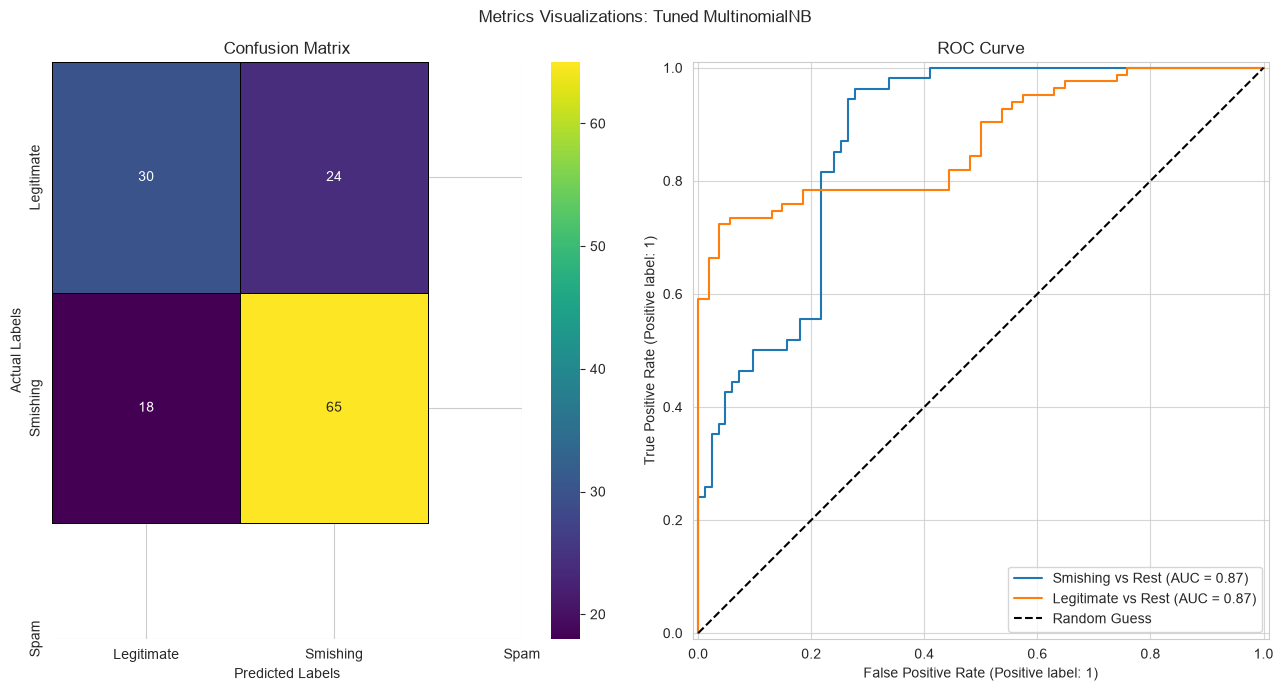

In [11]:
cm = confusion_matrix(y_test, ypred_mnb)

show_metrics(y_test, ypred_mnb, yprob_mnb[:, 1])
visualize_metrics(best_mnb, cm, X_test, y_test, 'Tuned MultinomialNB',
                  labels=['Smishing', 'Legitimate'])

## Tuned Complement Naive Bayes

Accuracy and ROC AUC Score
Accuracy Score: 74.510%
ROC AUC Score: 89.248%
              precision    recall  f1-score   support

           0       0.74      0.69      0.71        54
           1       0.76      0.79      0.77        82
           2       0.74      0.74      0.74        68

    accuracy                           0.75       204
   macro avg       0.74      0.74      0.74       204
weighted avg       0.74      0.75      0.74       204



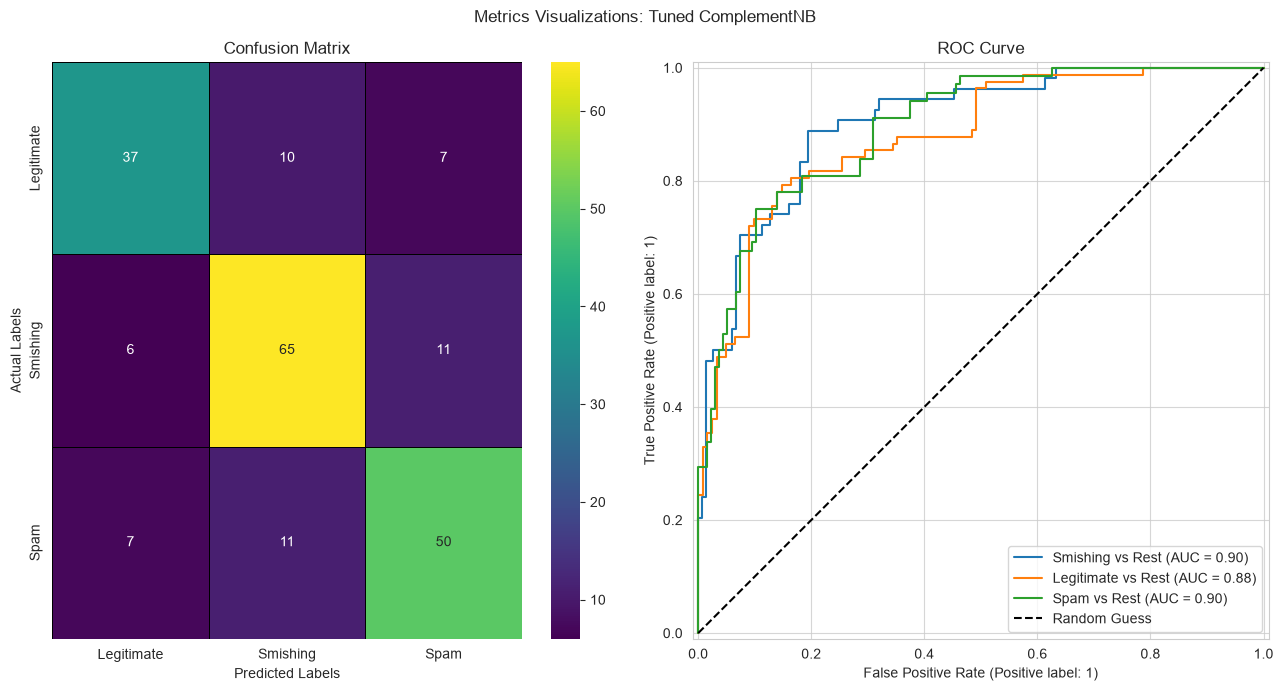

In [29]:
cm = confusion_matrix(y_test, ypred_cnb)

show_metrics(y_test, ypred_cnb, yprob_cnb)
visualize_metrics(best_cnb, cm, X_test, y_test, 'Tuned ComplementNB',
                  labels=['Smishing', 'Legitimate', 'Spam'])

## Tuned Random Forest Classifier

In [33]:
preprocessing = ColumnTransformer([
    ('text', TfidfVectorizer(ngram_range=(1,4), min_df=2, max_df=0.8, sublinear_tf=True), 'text'),
    ('scaler', MinMaxScaler(clip=True), numericals),
    ('bin', 'passthrough', binary_cols)
])

rf = Pipeline([
    ('preprocessor', preprocessing),
    ('rf', RandomForestClassifier())
])

rf_params = {
    'rf__criterion' : ['gini', 'entropy', 'log_loss'],
    'rf__max_depth' : [None, 100, 200, 300, 500],
    'rf__n_estimators': [100, 200, 400],
    'rf__min_samples_split': [2, 4, 6, 10],
    'rf__min_samples_leaf': [1, 2, 4, 8],
    'rf__max_features': ['sqrt', 'log2'],
    'rf__class_weight': [None, 'balanced']
}

best_rf, ypred_rf, yprob_rf = tune_search(
    X_train, y_train, X_test, train_groups,
    rf, rf_params
)

Fitting 5 folds for each of 2880 candidates, totalling 14400 fits
Model Best Parameters: {'rf__class_weight': None, 'rf__criterion': 'entropy', 'rf__max_depth': 100, 'rf__max_features': 'log2', 'rf__min_samples_leaf': 1, 'rf__min_samples_split': 4, 'rf__n_estimators': 200}


Accuracy and ROC AUC Score
Accuracy Score: 71.078%
ROC AUC Score: 89.344%
              precision    recall  f1-score   support

           0       0.75      0.70      0.72        54
           1       0.71      0.73      0.72        82
           2       0.68      0.69      0.69        68

    accuracy                           0.71       204
   macro avg       0.71      0.71      0.71       204
weighted avg       0.71      0.71      0.71       204



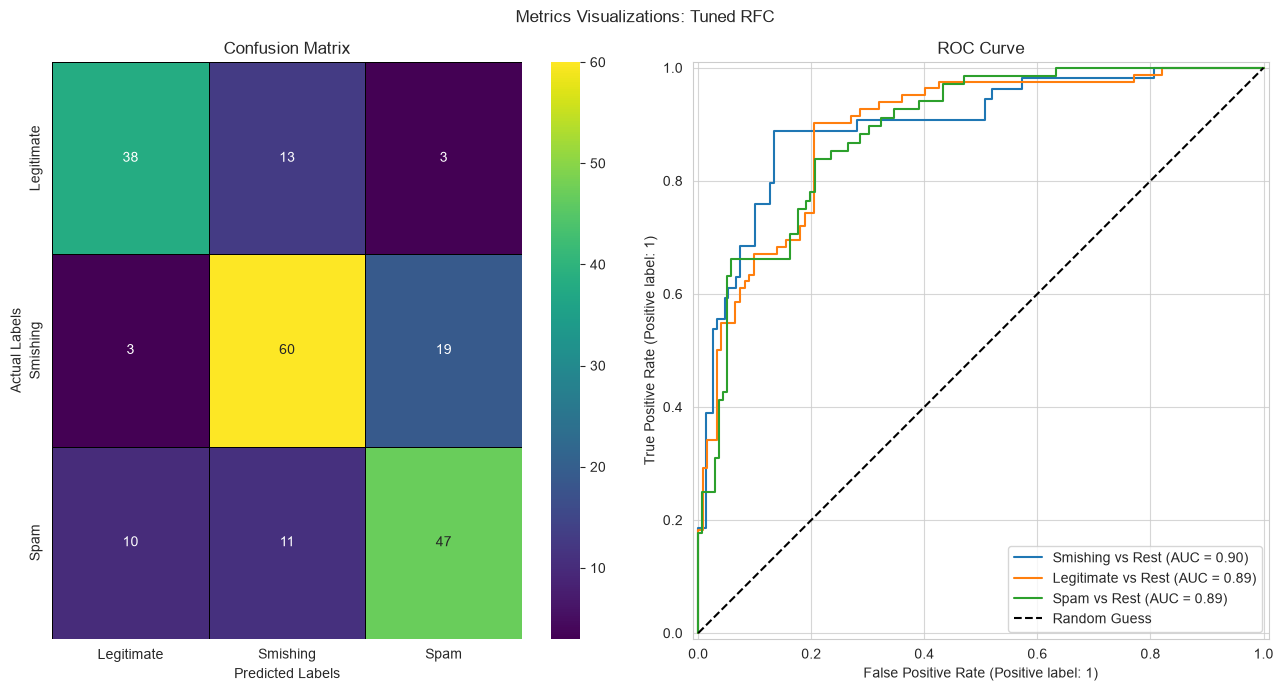

In [34]:
cm = confusion_matrix(y_test, ypred_rf)

show_metrics(y_test, ypred_rf, yprob_rf)
visualize_metrics(best_rf, cm, X_test, y_test, 'Tuned RFC',
                  labels=['Smishing', 'Legitimate', 'Spam'])